# 02 — Price Composition & Comparable Residential Price Change
**Dubai Real Estate Analytics V2 · Research Questions RQ01 and RQ02**

**Scope:** Registered Unit/Villa residential sales, principally 2021 versus 2025; completed-year historical context 2010–2025. This notebook estimates changes *among observed comparable transaction groups*, not appreciation of identical dwellings. It cannot isolate physical-quality changes within a group or claim a causal effect. Every published estimate must carry its population, coverage, estimator and robustness restrictions. **Source observations are never overwritten or imputed.**

## 02 — Prespecified estimands and mathematical contract

1. **Unadjusted:** transaction-level median `price_per_sqm` among P1 Strict residential sales (not the ratio of medians).
2. **Matched fixed-composition:** geometric aggregate of 2021-to-2025 changes in *group medians* of AED/sqm, using the same matched groups and fixed 2021 transaction-count weights in both endpoints: $\exp(\sum_g w_{g,2021}[\log m_{g,2025}-\log m_{g,2021}])-1$.
3. **Symmetric decomposition:** within a specified common-support universe, $\overline{\log p}_t=\sum_g s_{g,t}\mu_{g,t}$ and $\Delta\overline{\log p}=\sum_g\bar s_g\Delta\mu_g+\sum_g\bar\mu_g\Delta s_g$. The same identity separately applies to $\log(\mathrm{area})$.

**The decomposition does not explain the change in the raw median; nor does a raw-minus-matched difference identify a causal 'mix effect'.** The mean-log decomposition is in log points, and its exponentiated total is a change in geometric-mean prices for its restricted support. Historical observations must not silently fill missing matched cells.

In [2]:
from pathlib import Path
import os, sys, platform, json, math, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'loader.py').exists() and (p/'data'/'raw'/'dld_sales_transactions.parquet').exists()), None)
if ROOT is None: raise FileNotFoundError('Run in Dubai_Real_Estate_Analytics_V2 repository or notebooks/ with src/ and data/raw present')
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
from src.loader import load_and_validate
from src.cleaning import clean_transactions, cohort_audit
from src.features import engineer_features
SHA = '8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e'
raw, source, validation = load_and_validate(root=ROOT, expected_sha256=SHA, strict=True)
assert validation.passed and source.sha256 == SHA
OUT = ROOT/'reports'/'tables'; FIG = ROOT/'reports'/'figures'; AGG=ROOT/'data'/'aggregates'
for p in (OUT,FIG,AGG): p.mkdir(parents=True,exist_ok=True)
SEED=202602; rng=np.random.default_rng(SEED)
manifest=pd.DataFrame([dict(source_sha256=source.sha256, n=len(raw), columns=len(raw.columns), python=platform.python_version(), pandas=pd.__version__, numpy=np.__version__, code='02_Price_Composition', random_seed=SEED)])
display(manifest)
print('Validator:',len(validation.errors),'errors;',len(validation.warnings),'warnings')

,source_sha256,n,columns,python,pandas,numpy,code,random_seed
0,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,1382848,20,3.11.18,2.3.3,2.4.6,02_Price_Composition,202602


Validator: 0 errors; 6 warnings


In [3]:
cleaned=clean_transactions(raw)
f=engineer_features(cleaned)
assert len(f)==len(raw) and f.index.equals(raw.index)
for col in raw.columns: pd.testing.assert_series_equal(raw[col], f[col], check_names=True)
cohorts=cohort_audit(cleaned)
primary_year=f['year'].between(2010,2025).fillna(False)
P1=(f['eligible_residential_strict'] & primary_year)
P2=(f['eligible_known_segment'] & primary_year)
assert not (P2 & ~P1).any()
assert np.isfinite(f.loc[P1,'price_per_sqm']).all() and (f.loc[P1,'price_per_sqm']>0).all()
assert (f.loc[P1,'area_sqm']>0).all()
counts=pd.DataFrame([{'population':'raw','n':len(raw)}, {'population':'P1 Strict 2010–2025','n':int(P1.sum())}, {'population':'P2 2010–2025','n':int(P2.sum())}])
display(counts); display(cohorts)
# Restrict subsequent heavy grouping to valid historical residential rows, retaining needed columns.
cols=['transaction_id','year','area_id','property_type_label','reg_type_label','rooms_bucket','area_sqm','price_aed','price_per_sqm','quality_flags']
res=f.loc[P1,cols].copy()
res['year']=res['year'].astype(int)
res['area_id']=res['area_id'].astype('string')
res['log_psm']=np.log(res['price_per_sqm'])
res['log_area']=np.log(res['area_sqm'])
res['room_known']=pd.to_numeric(res['rooms_bucket'],errors='coerce').isin([0,1,2,3,4,5])
res['key_known']=res['area_id'].notna() & res['property_type_label'].isin(['Unit','Villa']) & res['reg_type_label'].isin(['Ready','Off-Plan'])
assert res['transaction_id'].is_unique

,population,n
0,raw,1382848
1,P1 Strict 2010–2025,901642
2,P2 2010–2025,864170


,cohort_id,parent,input_n,retained_n,excluded_n
0,P0_ALL_SALES,raw source,1382848,1382848,0
1,P1_RESIDENTIAL_CORE,P0_ALL_SALES,1382848,1113177,269671
2,P1_STRICT,P1_RESIDENTIAL_CORE,1113177,1094417,18760
3,P2_KNOWN_SEGMENT,P1_STRICT,1094417,1041009,53408
4,P3_AMENITY_KNOWN,P1_STRICT,1094417,712512,381905
5,P4_2026_PROVISIONAL,P0_ALL_SALES,1382848,136035,1246813


## 05 — Protocol freeze before price comparisons
The 2021 and 2025 endpoints, eligibility conditions, size bins, 2021 reference weights, matching thresholds (20/30/50/100) and bootstrap seed are prespecified. Feasibility ranking uses **only cell counts, endpoint coverage, effective weight concentration and segment coverage**—never realized price changes.

Designs: A = community/type/registration; B = A + bedrooms; C = A + coarse area band (no mandatory bedrooms); D = C + bedrooms; E = A + bedrooms + finer area band. Design C is the *preferred candidate*, conditional on its feasibility. The 60% coverage threshold is a provisional screen, not a population-validity theorem. Prefer restricted claims over extrapolating unsupported properties.

## 06 — Cohort-selection contract
Three losses must remain distinct for **each endpoint and each design**: (i) fields unavailable, (ii) group observed in only one year, and (iii) group below the prespecified transaction threshold. Report total matched coverage relative to P1 Strict, conditional coverage among feature-eligible transactions, and stratified Unit/Villa and Ready/Off-Plan coverage. The room-missing population is never imputed.

In [4]:
endpoint=res[res['year'].isin([2021,2025])].copy()
base_keys=['area_id','property_type_label','reg_type_label']
coverage_rows=[]
for year,part in res.groupby('year',sort=True):
    for (ptype,reg),sub in part.groupby(['property_type_label','reg_type_label'],dropna=False):
        coverage_rows.append(dict(year=int(year),property_type=str(ptype),registration=str(reg),strict_n=len(sub),key_n=int(sub.key_known.sum()),known_rooms_n=int(sub.room_known.sum()),known_rooms_key_n=int((sub.room_known & sub.key_known).sum())))
price_cohort_coverage=pd.DataFrame(coverage_rows)
price_cohort_coverage['bedroom_retention_pct']=100*price_cohort_coverage.known_rooms_n/price_cohort_coverage.strict_n
assert price_cohort_coverage.groupby('year').strict_n.sum().equals(res.groupby('year').size().rename('strict_n'))
display(price_cohort_coverage.query('year in [2021,2025]').sort_values(['year','property_type','registration']))

,year,property_type,registration,strict_n,key_n,known_rooms_n,known_rooms_key_n,bedroom_retention_pct
44,2021,Unit,Off-Plan,16417,16417,16417,16417,100.000000
45,2021,Unit,Ready,19129,19129,19081,19081,99.749072
46,2021,Villa,Off-Plan,5237,5237,5234,5234,99.942715
47,2021,Villa,Ready,5519,5519,3008,3008,54.502627
60,2025,Unit,Off-Plan,119449,119449,119444,119444,99.995814
61,2025,Unit,Ready,43873,43873,43822,43822,99.883755
62,2025,Villa,Off-Plan,9113,9113,9112,9112,99.989027
63,2025,Villa,Ready,6527,6527,4633,4633,70.982074


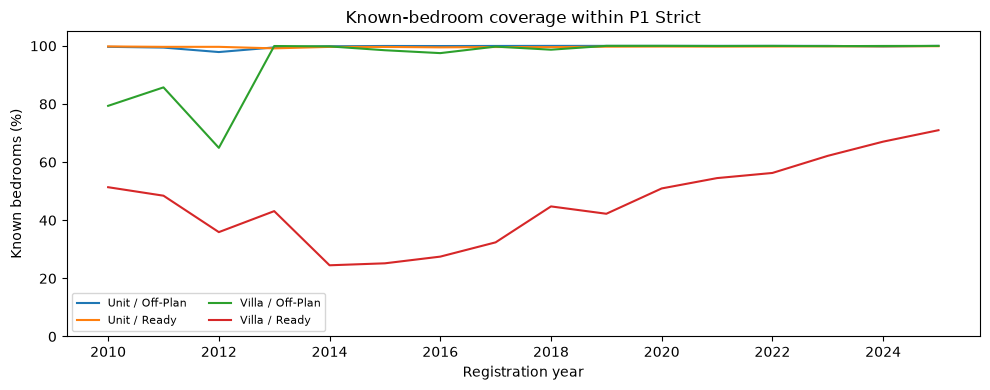

,year,property_type,registration,bedrooms_known,n,median_area,median_price,median_psm
88,2021,Villa,Off-Plan,False,3,439.43,2443075.0,5559.645450
89,2021,Villa,Off-Plan,True,5234,174.00,1689000.0,9293.650693
90,2021,Villa,Ready,False,2511,451.45,3000000.0,7276.471598
91,2021,Villa,Ready,True,3008,259.90,2350000.0,8862.232327
119,2025,Villa,Off-Plan,False,1,296.83,4138574.0,13942.573190
120,2025,Villa,Off-Plan,True,9112,187.26,3529888.0,16202.898551
121,2025,Villa,Ready,False,1894,594.58,5500000.0,11597.261649
122,2025,Villa,Ready,True,4633,209.07,3375000.0,16062.413951


In [5]:
missingness_rows=[]
for (year,ptype,reg),part in res.groupby(['year','property_type_label','reg_type_label'],dropna=False):
    for known,sub in part.groupby('room_known'):
        missingness_rows.append(dict(year=int(year),property_type=str(ptype),registration=str(reg),bedrooms_known=bool(known),n=len(sub),median_area=sub.area_sqm.median(),median_price=sub.price_aed.median(),median_psm=sub.price_per_sqm.median()))
room_selection=pd.DataFrame(missingness_rows)
fig,ax=plt.subplots(figsize=(10,4))
for (ptype,reg),sub in price_cohort_coverage.groupby(['property_type','registration']):
    if sub['year'].between(2010,2025).any(): ax.plot(sub.year,sub.bedroom_retention_pct,label=f'{ptype} / {reg}')
ax.set(title='Known-bedroom coverage within P1 Strict',ylabel='Known bedrooms (%)',xlabel='Registration year',ylim=(0,105));ax.legend(fontsize=8,ncol=2)
fig.tight_layout();fig.savefig(FIG/'02_bedroom_retention.png',dpi=145);plt.show()
display(room_selection.query("year in [2021,2025] and property_type == 'Villa'"))
# Descriptive evidence only; unequal groups do not identify the missingness mechanism.

In [6]:
# Fixed, interpretable physical area bins; identical across calendar years.
# Distinct Unit and Villa bands limit misleading comparisons across different size scales.
COARSE={'Unit':[0,45,65,90,125,175,250,np.inf], 'Villa':[0,150,225,300,400,550,750,1100,np.inf]}
FINE={'Unit':[0,35,45,55,65,80,90,110,125,150,175,225,300,np.inf], 'Villa':[0,120,150,185,225,265,300,350,400,475,550,650,750,925,1100,1500,np.inf]}
for name,binspec in [('coarse',COARSE),('fine',FINE)]:
    out=pd.Series(pd.NA,index=res.index,dtype='string')
    for ptype,bins in binspec.items():
        m=res.property_type_label.eq(ptype)
        labels=[f'{ptype}:{i:02d}' for i in range(len(bins)-1)]
        out.loc[m]=pd.cut(res.loc[m,'area_sqm'],bins=bins,labels=labels,include_lowest=False,right=True).astype('string')
    res['size_'+name]=out
assert res.loc[res.key_known,'size_coarse'].notna().all()
endpoint=res[res['year'].isin([2021,2025])].copy()  # refresh after adding fixed bands
DESIGNS={
 'A_broad':base_keys,
 'B_bedrooms':base_keys+['rooms_bucket'],
 'C_size_only':base_keys+['size_coarse'],
 'D_size_bedrooms':base_keys+['size_coarse','rooms_bucket'],
 'E_fine_bedrooms':base_keys+['size_fine','rooms_bucket']
}
def eligible_for_design(frame,name):
    keys=DESIGNS[name]
    mask=frame[keys].notna().all(axis=1) & frame.key_known
    if 'rooms_bucket' in keys: mask &= frame.room_known
    return frame.loc[mask].copy()
design_registry=pd.DataFrame([dict(design=k,keys=' | '.join(v),needs_bedrooms='rooms_bucket' in v,all_year_eligible_n=len(eligible_for_design(res,k))) for k,v in DESIGNS.items()])
display(design_registry)
assert design_registry.design.is_unique

,design,keys,needs_bedrooms,all_year_eligible_n
0,A_broad,area_id | property_type_label | reg_type_label,False,901642
1,B_bedrooms,area_id | property_type_label | reg_type_label...,True,864170
2,C_size_only,area_id | property_type_label | reg_type_label...,False,901642
3,D_size_bedrooms,area_id | property_type_label | reg_type_label...,True,864170
4,E_fine_bedrooms,area_id | property_type_label | reg_type_label...,True,864170


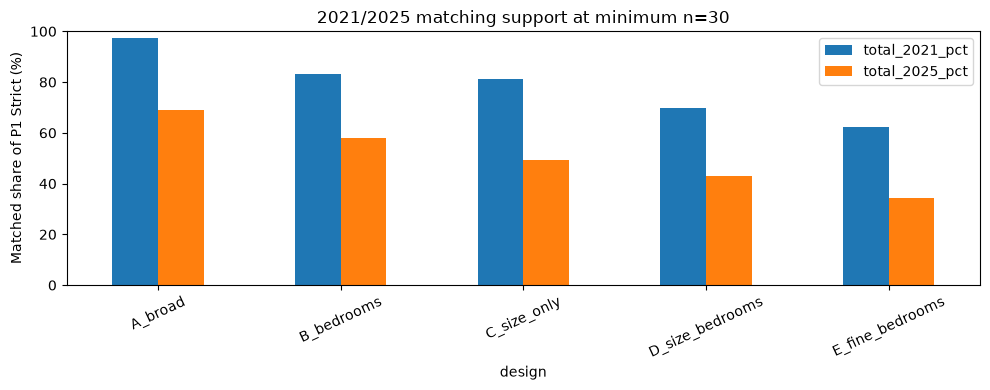

,design,threshold,matched_cells,feature_2021_n,feature_2025_n,common_2021_n,common_2025_n,matched_2021_n,matched_2025_n,feature_2021_pct,feature_2025_pct,conditional_match_2021_pct,conditional_match_2025_pct,total_2021_pct,total_2025_pct,effective_segments,top5_weight_pct
1,A_broad,30,102,46302,178962,45765,150086,45119,123661,100.000000,100.000000,97.445035,69.099027,97.445035,69.099027,39.067201,25.446043
5,B_bedrooms,30,200,43740,177011,42492,137776,38525,103902,94.466762,98.909824,88.077275,58.698047,83.203749,58.058135,85.928426,13.791045
9,C_size_only,30,248,46302,178962,44733,133914,37556,87951,100.000000,100.000000,81.110967,49.145070,81.110967,49.145070,116.627715,10.078283
13,D_size_bedrooms,30,250,43740,177011,41871,122647,32387,77258,94.466762,98.909824,74.044353,43.645875,69.947302,43.170058,114.153818,10.822243
17,E_fine_bedrooms,30,263,43740,177011,41329,112206,28935,61731,94.466762,98.909824,66.152263,34.874104,62.491901,34.493915,122.780430,10.333506


In [7]:
def matched_support(frame, keys, min_n):
    ct=frame.groupby(keys+['year'],dropna=False,observed=True).size().unstack('year',fill_value=0)
    for year in [2021,2025]:
        if year not in ct.columns:ct[year]=0
    common=(ct[2021]>0)&(ct[2025]>0)
    good=(ct[2021]>=min_n)&(ct[2025]>=min_n)
    return ct,common,good
support_rows=[]; support_cache={}
for design,keys in DESIGNS.items():
    v=eligible_for_design(endpoint,design)
    ct,common,_=matched_support(v,keys,1)
    for min_n in (20,30,50,100):
        good=(ct[2021]>=min_n)&(ct[2025]>=min_n)
        weights=ct.loc[good,2021].astype(float)
        weights=weights/weights.sum() if weights.sum()>0 else weights
        totals={year:int((endpoint.year==year).sum()) for year in (2021,2025)}
        elig={year:int((v.year==year).sum()) for year in (2021,2025)}
        both={year:int(ct.loc[common,year].sum()) for year in (2021,2025)}
        matched={year:int(ct.loc[good,year].sum()) for year in (2021,2025)}
        support_rows.append(dict(design=design,threshold=min_n,matched_cells=int(good.sum()),feature_2021_n=elig[2021],feature_2025_n=elig[2025],common_2021_n=both[2021],common_2025_n=both[2025],matched_2021_n=matched[2021],matched_2025_n=matched[2025],feature_2021_pct=100*elig[2021]/totals[2021],feature_2025_pct=100*elig[2025]/totals[2025],conditional_match_2021_pct=100*matched[2021]/elig[2021] if elig[2021] else np.nan,conditional_match_2025_pct=100*matched[2025]/elig[2025] if elig[2025] else np.nan,total_2021_pct=100*matched[2021]/totals[2021],total_2025_pct=100*matched[2025]/totals[2025],effective_segments=1/(weights.pow(2).sum()) if len(weights) else np.nan,top5_weight_pct=100*weights.nlargest(5).sum() if len(weights) else np.nan))
        support_cache[(design,min_n)]=(ct,good)
price_matching_feasibility=pd.DataFrame(support_rows)
assert price_matching_feasibility[['total_2021_pct','total_2025_pct']].le(100.00001).all().all()
fig,ax=plt.subplots(figsize=(10,4));p=price_matching_feasibility.query('threshold==30').set_index('design')
p[['total_2021_pct','total_2025_pct']].plot.bar(ax=ax);ax.set(ylabel='Matched share of P1 Strict (%)',title='2021/2025 matching support at minimum n=30',ylim=(0,100));ax.tick_params(axis='x',rotation=25);fig.tight_layout();fig.savefig(FIG/'02_matching_coverage.png',dpi=145);plt.show()
display(price_matching_feasibility.query('threshold==30'))

## 11 — Pre-outcome specification decision
**Protocol:** Minimum 30 transactions per matched cell in *both* endpoints, at least 30 cells, at least 60% P1 Strict coverage at both endpoints, and an effective segment count of at least 10 are screening criteria, not guarantees. Prefer design **C** if it passes; otherwise use **A** if it passes; otherwise the best-supported controlled design may be displayed only as a restricted exploratory result. All A–E results remain visible. The code below will freeze the preference using support statistics alone. No realized price-change result is consulted in choosing the primary candidate.

## 12 — Raw residential benchmark contract
Transaction-level median AED/sqm is computed from P1 Strict only and is **not** the median sale consideration divided by the median transaction area. Unadjusted annual quantiles and Unit/Villa and Ready/Off-Plan distributions diagnose the mix entering sales. Comparisons of raw pooled medians with grouped estimates are contrasts of different estimands; not an identified composition decomposition.

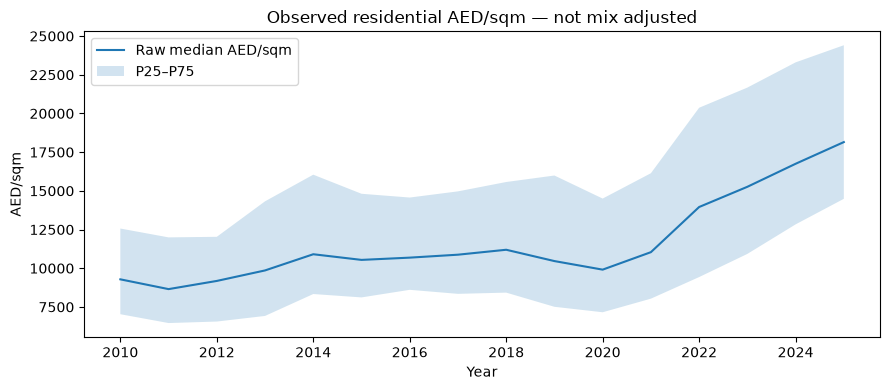

,year,n,mean_psm,median_psm,mean_price,median_price,p10_psm,p25_psm,p50_psm,p75_psm,p90_psm
9,2019,30661,12084.992533,10461.872288,1.475474e+06,1130000.0,5556.606450,7508.352449,10461.872288,15989.948893,20288.439421
10,2020,26137,11296.337067,9908.945052,1.459983e+06,1100000.0,5215.382745,7155.555556,9908.945052,14500.967118,18803.688169
11,2021,46302,12773.696534,11037.735849,1.778190e+06,1316824.0,5796.748318,8033.839080,11037.735849,16138.047793,21851.572512
12,2022,73415,15716.262441,13955.342903,1.950101e+06,1422583.0,6800.266963,9428.985646,13955.342903,20367.855820,26320.804382
13,2023,106643,17301.972084,15261.251940,2.004905e+06,1420000.0,8261.935236,10925.408631,15261.251940,21671.234688,28172.170415
14,2024,152600,18327.227542,16747.751732,1.947063e+06,1404746.5,9875.708381,12832.617803,16747.751732,23299.748111,28504.895781
15,2025,178962,19937.717081,18149.523543,1.999992e+06,1380000.0,11457.668911,14484.215730,18149.523543,24407.680292,30462.149591


In [8]:
# 13 — Overall raw price distribution, P1 Strict, nominal AED/sqm.
qs=[.10,.25,.50,.75,.90]
raw_residential_price_yearly=(res.groupby('year').agg(n=('price_per_sqm','size'),mean_psm=('price_per_sqm','mean'),median_psm=('price_per_sqm','median'),mean_price=('price_aed','mean'),median_price=('price_aed','median')).reset_index())
for q in qs:raw_residential_price_yearly[f'p{int(q*100):02d}_psm']=res.groupby('year').price_per_sqm.quantile(q).to_numpy()
fig,ax=plt.subplots(figsize=(9,4));ax.plot(raw_residential_price_yearly.year,raw_residential_price_yearly.median_psm,label='Raw median AED/sqm');ax.fill_between(raw_residential_price_yearly.year.to_numpy(),raw_residential_price_yearly.p25_psm.to_numpy(),raw_residential_price_yearly.p75_psm.to_numpy(),alpha=.2,label='P25–P75');ax.set(title='Observed residential AED/sqm — not mix adjusted',ylabel='AED/sqm',xlabel='Year');ax.legend();fig.tight_layout();fig.savefig(FIG/'02_raw_price_distribution.png',dpi=145);plt.show();display(raw_residential_price_yearly.tail(7))

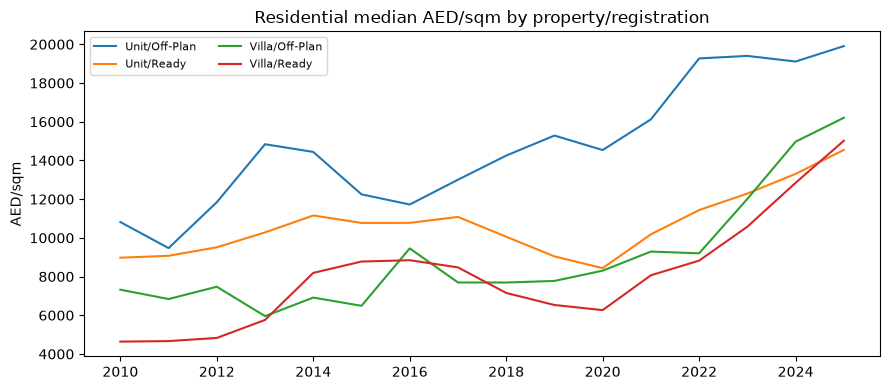

,year,property_type_label,reg_type_label,n,median_psm,mean_psm,median_price,p10_psm,p25_psm,p75_psm,p90_psm
44,2021,Unit,Off-Plan,16417,16120.365395,16964.265531,1087800.0,8855.278989,10956.147198,20384.695798,27349.280524
45,2021,Unit,Ready,19129,10180.088345,11205.771506,995361.0,4815.295645,6815.294816,13993.126291,19094.103996
46,2021,Villa,Off-Plan,5237,9291.161151,9835.599018,1690000.0,6745.710545,7747.607115,11900.234726,13393.959203
47,2021,Villa,Ready,5519,8065.698783,8530.732832,2556026.0,5005.298838,6458.333333,9939.625499,12356.348510
60,2025,Unit,Off-Plan,119449,19905.287714,21656.058749,1348888.0,13854.878206,15913.320126,26187.031435,31770.306991
61,2025,Unit,Ready,43873,14538.676608,16502.786234,1090000.0,8119.226200,10533.875988,20957.038072,27419.885057
62,2025,Villa,Off-Plan,9113,16202.898551,17156.923647,3529888.0,11735.294118,13898.111456,19281.545303,24305.035971
63,2025,Villa,Ready,6527,15015.974441,15462.138372,3650000.0,8038.483883,11846.940791,18523.927145,23078.800722


In [9]:
price_distribution_by_segment=(res.groupby(['year','property_type_label','reg_type_label'],dropna=False).agg(n=('price_per_sqm','size'),median_psm=('price_per_sqm','median'),mean_psm=('price_per_sqm','mean'),median_price=('price_aed','median')).reset_index())
for q in (.1,.25,.75,.9):
    v=res.groupby(['year','property_type_label','reg_type_label'],dropna=False)['price_per_sqm'].quantile(q).rename(f'p{int(q*100)}_psm').reset_index()
    price_distribution_by_segment=price_distribution_by_segment.merge(v,on=['year','property_type_label','reg_type_label'],validate='one_to_one')
fig,ax=plt.subplots(figsize=(9,4))
for (p,r),g in price_distribution_by_segment.groupby(['property_type_label','reg_type_label']):
    ax.plot(g.year,g.median_psm,label=f'{p}/{r}')
ax.set(title='Residential median AED/sqm by property/registration',ylabel='AED/sqm');ax.legend(ncol=2,fontsize=8);fig.tight_layout();fig.savefig(FIG/'02_segment_price_distribution.png',dpi=145);plt.show()
display(price_distribution_by_segment.query('year in [2021,2025]'))

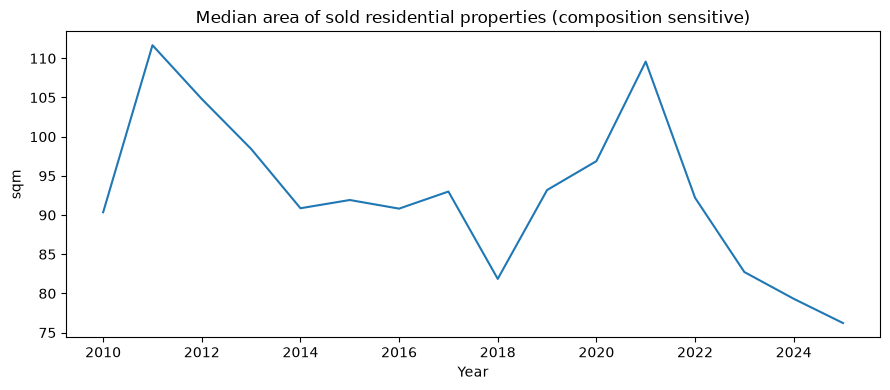

,year,n,mean_area,median_area,p10_area,p25_area,p75_area,p90_area
11,2021,46302,148.932679,109.58,42.39,68.54,174.00,265.04
15,2025,178962,102.502924,76.22,38.07,52.37,115.46,174.00


,year,size,sum,unknown_share_pct
11,2021,46302,43740,5.533238
15,2025,178962,177011,1.090176


In [10]:
area_distribution_yearly=res.groupby('year').agg(n=('area_sqm','size'),mean_area=('area_sqm','mean'),median_area=('area_sqm','median')).reset_index()
for q in (.1,.25,.75,.9):area_distribution_yearly[f'p{int(q*100)}_area']=res.groupby('year').area_sqm.quantile(q).to_numpy()
residential_size_mix=(res.groupby(['year','property_type_label','reg_type_label','room_known','size_coarse'],dropna=False,observed=True).size().rename('n').reset_index())
room_missing_by_year=res.groupby('year').room_known.agg(['size','sum']).reset_index();room_missing_by_year['unknown_share_pct']=100*(1-room_missing_by_year['sum']/room_missing_by_year['size'])
fig,ax=plt.subplots(figsize=(9,4));ax.plot(area_distribution_yearly.year,area_distribution_yearly.median_area);ax.set(title='Median area of sold residential properties (composition sensitive)',ylabel='sqm',xlabel='Year');fig.tight_layout();fig.savefig(FIG/'02_area_distribution.png',dpi=145);plt.show()
display(area_distribution_yearly.query('year in [2021,2025]'));display(room_missing_by_year.query('year in [2021,2025]'))

In [11]:
baseline_mix=(endpoint.groupby(['year','property_type_label','reg_type_label']).agg(n=('transaction_id','size'),median_psm=('price_per_sqm','median'),median_area=('area_sqm','median')).reset_index())
baseline_mix['share_pct']=100*baseline_mix['n']/baseline_mix.groupby('year')['n'].transform('sum')
pv=baseline_mix.pivot_table(index=['property_type_label','reg_type_label'],columns='year',values=['n','share_pct','median_psm'],aggfunc='first')
display(pv)
print('The change in a pooled median does not decompose into changes in these category medians.')

median_psm                    n          \
year                                        2021          2025   2021    2025   
property_type_label reg_type_label                                              
Unit                Off-Plan        16120.365395  19905.287714  16417  119449   
                    Ready           10180.088345  14538.676608  19129   43873   
Villa               Off-Plan         9291.161151  16202.898551   5237    9113   
                    Ready            8065.698783  15015.974441   5519    6527   

                                    share_pct             
year                                     2021       2025  
property_type_label reg_type_label                        
Unit                Off-Plan        35.456352  66.745454  
                    Ready           41.313550  24.515260  
Villa               Off-Plan        11.310527   5.092142  
                    Ready           11.919572   3.647143

The change in a pooled median does not decompose into changes in these category medians.


## 17 — Matched fixed-composition index
For group $g$, $m_{g,t}$ is its **transaction median** AED/sqm. The endpoint log return $r_g=\log(m_{g,2025}/m_{g,2021})$ is averaged using reference $w_{g,2021}=n_{g,2021}/\sum_{h\in S}n_{h,2021}$ over the *same supported set* $S$ in both years. An estimate is a change **among observed matched categories**, with residual within-cell property heterogeneity and changing building quality unmeasured. The raw median and this index are different estimands.

In [12]:
# Freeze preferred candidate solely using previously computed support, not prices.
feas=price_matching_feasibility.query('threshold==30').set_index('design')
feas_ok=(feas.matched_cells>=30)&(feas.total_2021_pct>=60)&(feas.total_2025_pct>=60)&(feas.effective_segments>=10)
if bool(feas_ok.get('C_size_only',False)): PRIMARY='C_size_only'
elif bool(feas_ok.get('A_broad',False)): PRIMARY='A_broad'
else: PRIMARY=None
print('Primary specification frozen from support only:',PRIMARY or 'NONE — only restricted exploratory estimates')
segment_stats={}; segment_samples={}
for design,keys in DESIGNS.items():
    v=eligible_for_design(endpoint,design)
    gs=(v.groupby(keys+['year'],dropna=False,observed=True).agg(n=('transaction_id','size'),median_psm=('price_per_sqm','median'),mean_log_psm=('log_psm','mean'),mean_log_area=('log_area','mean')).reset_index())
    assert gs['median_psm'].gt(0).all() and not gs.duplicated(keys+['year']).any()
    segment_stats[design]=gs;segment_samples[design]=v
price_segment_yearly=pd.concat([v.assign(design=k) for k,v in segment_stats.items()],ignore_index=True)
display(price_segment_yearly.groupby('design').agg(group_periods=('n','size'),transactions=('n','sum')))

Primary specification frozen from support only: A_broad


,group_periods,transactions
design,,
A_broad,404,225264
B_bedrooms,1072,220751
C_size_only,1885,225264
D_size_bedrooms,2894,220751
E_fine_bedrooms,4298,220751


In [13]:
def endpoint_index(design, threshold=30, weight_mode='base', sample=None, restrict_to=None):
    keys=DESIGNS[design]
    v=eligible_for_design(endpoint,design) if sample is None else sample.copy()
    v=v.loc[v.year.isin([2021,2025])]
    if restrict_to is not None:
        col,value=restrict_to;v=v[v[col].eq(value)]
    if v.empty:return None
    g=v.groupby(keys+['year'],observed=True,dropna=False).agg(n=('price_per_sqm','size'),med=('price_per_sqm','median')).reset_index()
    wide_n=g.pivot(index=keys,columns='year',values='n').fillna(0)
    good=wide_n.get(2021,pd.Series(0,index=wide_n.index)).ge(threshold)&wide_n.get(2025,pd.Series(0,index=wide_n.index)).ge(threshold)
    if not good.any():return None
    wide_m=g.pivot(index=keys,columns='year',values='med').loc[good]
    n0=wide_n.loc[good,2021];n1=wide_n.loc[good,2025]
    if weight_mode=='base':weights=n0/n0.sum()
    elif weight_mode=='end':weights=n1/n1.sum()
    elif weight_mode=='symmetric':weights=(n0/n0.sum()+n1/n1.sum())/2
    elif weight_mode=='equal':weights=pd.Series(1/len(n0),index=n0.index)
    else:raise ValueError('Unknown weight mode')
    lr=np.log(wide_m[2025]/wide_m[2021]);delta=float(np.dot(weights.to_numpy(),lr.to_numpy()))
    p1={y:int((endpoint.year.eq(y) & (endpoint[restrict_to[0]].eq(restrict_to[1]) if restrict_to else True)).sum()) for y in (2021,2025)}
    covered={2021:int(n0.sum()),2025:int(n1.sum())}
    row=dict(design=design,threshold=threshold,weight_mode=weight_mode,segment=restrict_to[1] if restrict_to else 'ALL',matched_cells=int(good.sum()),n_2021=covered[2021],n_2025=covered[2025],coverage_2021_pct=100*covered[2021]/p1[2021] if p1[2021] else np.nan,coverage_2025_pct=100*covered[2025]/p1[2025] if p1[2025] else np.nan,log_change=delta,change_pct=100*np.expm1(delta),effective_segments=1/float((weights**2).sum()),top5_weight_pct=100*weights.nlargest(5).sum())
    details=pd.DataFrame({'n_2021':n0,'n_2025':n1,'median_2021':wide_m[2021],'median_2025':wide_m[2025],'weight':weights,'log_change':lr,'weighted_contribution':weights*lr}).reset_index()
    assert np.isclose(details.weight.sum(),1) and np.isclose(details.weighted_contribution.sum(),delta)
    return row,details
all_indices=[]; detail_indices={}
for d in DESIGNS:
    ans=endpoint_index(d,30)
    if ans:
        row,det=ans;all_indices.append(row);detail_indices[d]=det
price_index_endpoint=pd.DataFrame(all_indices)
if PRIMARY is not None and PRIMARY not in detail_indices:raise AssertionError('Preselected supported design produced no index')
display(price_index_endpoint)

,design,threshold,weight_mode,segment,matched_cells,n_2021,n_2025,coverage_2021_pct,coverage_2025_pct,log_change,change_pct,effective_segments,top5_weight_pct
0,A_broad,30,base,ALL,102,45119,123661,97.445035,69.099027,0.499604,64.806811,39.067201,25.446043
1,B_bedrooms,30,base,ALL,200,38525,103902,83.203749,58.058135,0.482167,61.958029,85.928426,13.791045
2,C_size_only,30,base,ALL,248,37556,87951,81.110967,49.145070,0.475460,60.875411,116.627715,10.078283
3,D_size_bedrooms,30,base,ALL,250,32387,77258,69.947302,43.170058,0.469070,59.850664,114.153818,10.822243
4,E_fine_bedrooms,30,base,ALL,263,28935,61731,62.491901,34.493915,0.470212,60.033272,122.780430,10.333506


In [14]:
index_subgroups=[]
for d in DESIGNS:
    for col in ['property_type_label','reg_type_label']:
        for value in ['Unit','Villa'] if col=='property_type_label' else ['Ready','Off-Plan']:
            ans=endpoint_index(d,30,restrict_to=(col,value))
            if ans:
                row,_=ans;row['subgroup_variable']=col;index_subgroups.append(row)
price_index_by_segment=pd.DataFrame(index_subgroups)
# Small samples remain visible but do not become publishable subgroup results automatically.
if not price_index_by_segment.empty:
    price_index_by_segment['support_flag']=(price_index_by_segment.matched_cells>=10)&(price_index_by_segment.coverage_2021_pct>=50)&(price_index_by_segment.coverage_2025_pct>=50)
display(price_index_by_segment.query("design == @PRIMARY") if PRIMARY else price_index_by_segment.head(12))

,design,threshold,weight_mode,segment,matched_cells,n_2021,n_2025,coverage_2021_pct,coverage_2025_pct,log_change,change_pct,effective_segments,top5_weight_pct,subgroup_variable,support_flag
0,A_broad,30,base,Unit,74,35243,112228,99.147583,68.715788,0.456937,57.922938,27.515164,32.576682,property_type_label,True
1,A_broad,30,base,Villa,28,9876,11433,91.818520,73.101023,0.651862,91.911138,13.999599,46.607938,property_type_label,True
2,A_broad,30,base,Ready,64,23675,47321,96.052418,93.890873,0.475397,60.865349,22.208747,38.382260,reg_type_label,True
3,A_broad,30,base,Off-Plan,38,21444,76340,99.030202,59.379910,0.526328,69.270598,17.113567,45.467264,reg_type_label,True


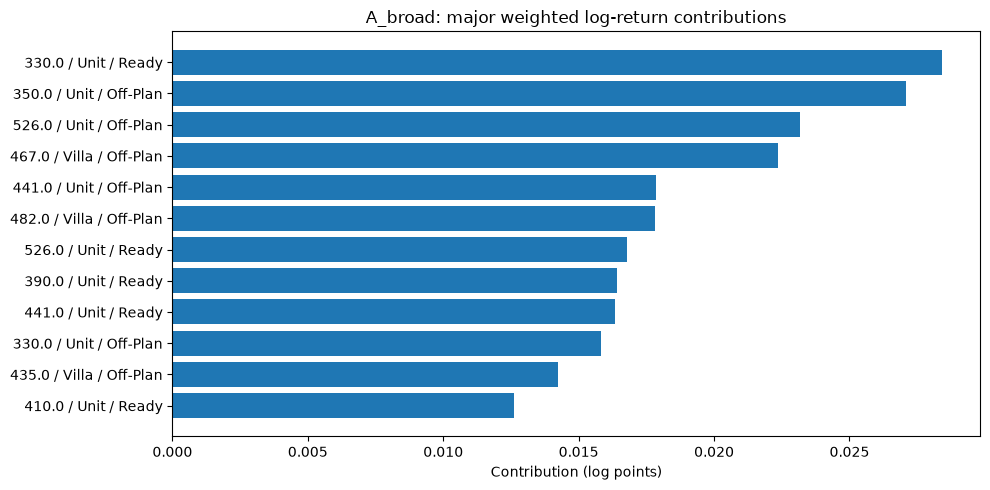

,area_id,property_type_label,reg_type_label,n_2021,n_2025,median_2021,median_2025,weight,log_change,weighted_contribution
8,330.0,Unit,Ready,3112.0,3529.0,13265.056381,20022.720818,0.068973,0.411734,0.028399
18,350.0,Unit,Off-Plan,1401.0,2363.0,10887.636081,26056.733524,0.031051,0.872648,0.027097
98,526.0,Unit,Off-Plan,1925.0,8570.0,16430.205950,28289.450998,0.042665,0.543368,0.023183
74,467.0,Villa,Off-Plan,1858.0,1628.0,9068.351635,15610.090576,0.041180,0.543127,0.022366
42,441.0,Unit,Off-Plan,1506.0,12071.0,9712.566619,16579.268617,0.033378,0.534732,0.017849
81,482.0,Villa,Off-Plan,715.0,51.0,11601.725685,35746.097815,0.015847,1.125287,0.017832
99,526.0,Unit,Ready,1983.0,2929.0,13993.076114,20496.003279,0.043950,0.381667,0.016774
29,390.0,Unit,Ready,1332.0,2403.0,14406.236926,25133.472084,0.029522,0.556539,0.016430
43,441.0,Unit,Ready,1525.0,5305.0,8454.286997,13716.938661,0.033800,0.483958,0.016358
7,330.0,Unit,Off-Plan,2344.0,3027.0,26284.832295,35634.743875,0.051952,0.304329,0.015810


In [15]:
price_index_contributions=pd.concat([v.assign(design=d) for d,v in detail_indices.items()],ignore_index=True) if detail_indices else pd.DataFrame()
if PRIMARY:
    top=detail_indices[PRIMARY].sort_values('weighted_contribution',key=lambda x:x.abs(),ascending=False).head(12)
    fig,ax=plt.subplots(figsize=(10,5));labels=top[DESIGNS[PRIMARY]].astype(str).agg(' / '.join,axis=1)
    ax.barh(labels.iloc[::-1],top.weighted_contribution.iloc[::-1]);ax.set(title=f'{PRIMARY}: major weighted log-return contributions',xlabel='Contribution (log points)');fig.tight_layout();fig.savefig(FIG/'02_index_contributions.png',dpi=145,bbox_inches='tight');plt.show()
    display(top)
else:print('No primary index passed support screen; component plot withheld.')

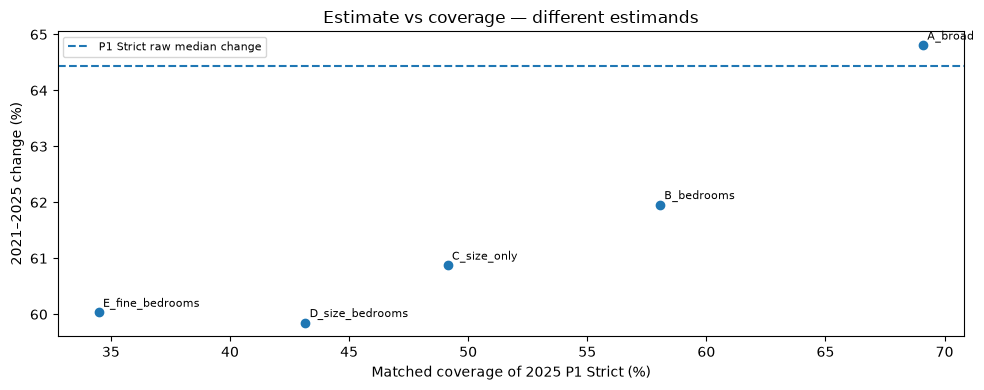

Raw residential median change: 64.432%


,design,threshold,weight_mode,segment,matched_cells,n_2021,n_2025,coverage_2021_pct,coverage_2025_pct,log_change,change_pct,effective_segments,top5_weight_pct,raw_P1_median_change_pct,primary_candidate
0,A_broad,30,base,ALL,102,45119,123661,97.445035,69.099027,0.499604,64.806811,39.067201,25.446043,64.431581,True
1,B_bedrooms,30,base,ALL,200,38525,103902,83.203749,58.058135,0.482167,61.958029,85.928426,13.791045,64.431581,False
2,C_size_only,30,base,ALL,248,37556,87951,81.110967,49.145070,0.475460,60.875411,116.627715,10.078283,64.431581,False
3,D_size_bedrooms,30,base,ALL,250,32387,77258,69.947302,43.170058,0.469070,59.850664,114.153818,10.822243,64.431581,False
4,E_fine_bedrooms,30,base,ALL,263,28935,61731,62.491901,34.493915,0.470212,60.033272,122.780430,10.333506,64.431581,False


In [16]:
raw0=raw_residential_price_yearly.set_index('year').loc[2021,'median_psm']
raw1=raw_residential_price_yearly.set_index('year').loc[2025,'median_psm']
raw_change_pct=100*(raw1/raw0-1)
price_comparison_summary=price_index_endpoint.copy()
price_comparison_summary['raw_P1_median_change_pct']=raw_change_pct
price_comparison_summary['primary_candidate']=(price_comparison_summary['design']==PRIMARY)
fig,ax=plt.subplots(figsize=(10,4));ax.axhline(raw_change_pct,ls='--',label='P1 Strict raw median change')
if not price_index_endpoint.empty:
    ax.scatter(price_index_endpoint.coverage_2025_pct,price_index_endpoint.change_pct)
    for _,r in price_index_endpoint.iterrows():ax.annotate(r.design,(r.coverage_2025_pct,r.change_pct),fontsize=8,xytext=(3,4),textcoords='offset points')
ax.set(xlabel='Matched coverage of 2025 P1 Strict (%)',ylabel='2021–2025 change (%)',title='Estimate vs coverage — different estimands');ax.legend(fontsize=8);fig.tight_layout();fig.savefig(FIG/'02_raw_vs_matched_price.png',dpi=145);plt.show()
print('Raw residential median change: %.3f%%'%raw_change_pct);display(price_comparison_summary)

## 23 — Matched-result interpretation gate
A numerically stable matched estimate can describe only its explicitly eligible population. We will never claim that a restricted geometric aggregate is identical-home appreciation. A reported adjusted estimate requires its matched-group count, 2021 and 2025 coverage, effective weighted segments, registration/type sensitivity, and a clear unmeasured-quality caveat. A contrast with the raw median **is not** an exact composition component.

## 24 — Exact symmetric decomposition of **mean log** AED/sqm
For a fixed set of observed groups with support in both years, with year-specific normalized transaction shares $s_{g,t}$ and within-group means $\mu_{g,t}$ of log AED/sqm, the exact arithmetic identity is:
$$\Delta\overline{\log p}=\sum_g\frac{s_{g,0}+s_{g,1}}2(\mu_{g,1}-\mu_{g,0})+\sum_g\frac{\mu_{g,0}+\mu_{g,1}}2(s_{g,1}-s_{g,0}).$$
This identity applies to the **restricted common-support population**, NOT the raw transaction median; unmatched groups are excluded and their coverage is separately documented. Choice of group definitions and log origin does not alter the total. The within component is not a causal effect.

In [17]:
# Decomposition uses common-support segments with observations in both endpoints,
# and optionally the same minimum support as the matched-index estimator.
def decomp_universe(design,threshold=30):
    v=eligible_for_design(endpoint,design);keys=DESIGNS[design]
    ct,common,good=matched_support(v,keys,threshold)
    if not good.any():return v.iloc[:0].copy(),pd.DataFrame()
    supported=ct.loc[good].reset_index()[keys]
    selected=v.merge(supported,on=keys,how='inner',validate='many_to_one')
    assert selected.year.isin([2021,2025]).all()
    return selected,ct.loc[good].reset_index()
DECOMP_DESIGN=PRIMARY if PRIMARY else ('C_size_only' if 'C_size_only' in DESIGNS else 'A_broad')
common_data,common_cells=decomp_universe(DECOMP_DESIGN)
price_decomposition_population=(common_data.groupby(['year','property_type_label','reg_type_label']).agg(n=('log_psm','size'),mean_log_psm=('log_psm','mean'),mean_log_area=('log_area','mean')).reset_index()) if not common_data.empty else pd.DataFrame()
coverage_decomp=pd.DataFrame([dict(year=y,matched_n=int(common_data.year.eq(y).sum()),strict_n=int(endpoint.year.eq(y).sum()),coverage_pct=100*common_data.year.eq(y).sum()/endpoint.year.eq(y).sum()) for y in (2021,2025)])
display(coverage_decomp)
assert not common_data.empty, 'No common-support data available: price/area decomposition correctly withheld'

,year,matched_n,strict_n,coverage_pct
0,2021,45119,46302,97.445035
1,2025,123661,178962,69.099027


Exact price decomposition (LOG POINTS, not median):


,design,metric,within_log_points,composition_log_points,total_log_points,geomean_change_pct,n_groups,n_2021,n_2025
0,A_broad,mean_log_AED_per_sqm,0.510535,-0.068032,0.442503,55.659928,102,45119,123661


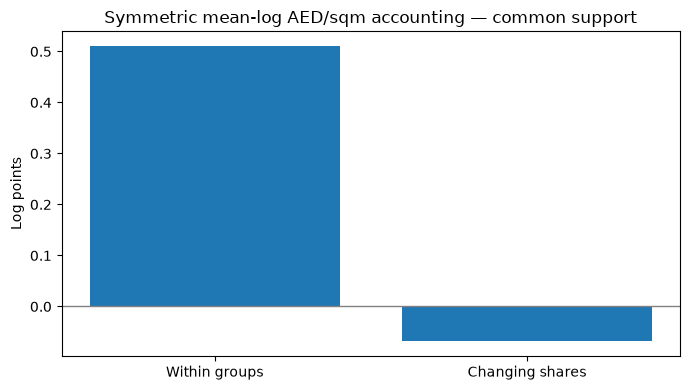

In [18]:
def symmetric_decomposition(data,keys,value_col):
    g=(data.groupby(keys+['year'],observed=True,dropna=False).agg(n=(value_col,'size'),mu=(value_col,'mean')).reset_index())
    w_n=g.pivot(index=keys,columns='year',values='n').fillna(0)
    w_mu=g.pivot(index=keys,columns='year',values='mu')
    assert w_n[[2021,2025]].gt(0).all().all()
    s0=w_n[2021]/w_n[2021].sum();s1=w_n[2025]/w_n[2025].sum()
    mu0=w_mu[2021];mu1=w_mu[2025]
    within=((s0+s1)/2)*(mu1-mu0)
    composition=((mu0+mu1)/2)*(s1-s0)
    direct=float((s1*mu1).sum()-(s0*mu0).sum())
    assert np.isclose(float(within.sum()+composition.sum()),direct,atol=1e-10)
    detail=pd.DataFrame(dict(share_2021=s0,share_2025=s1,mean_log_2021=mu0,mean_log_2025=mu1,within_log_points=within,composition_log_points=composition)).reset_index()
    total=dict(within_log_points=float(within.sum()),composition_log_points=float(composition.sum()),total_log_points=direct,geomean_change_pct=100*np.expm1(direct),n_groups=len(detail),n_2021=int(w_n[2021].sum()),n_2025=int(w_n[2025].sum()))
    return total,detail
price_decomp_total,price_decomp_detail=symmetric_decomposition(common_data,DESIGNS[DECOMP_DESIGN],'log_psm')
price_mix_decomposition=pd.DataFrame([dict(design=DECOMP_DESIGN,metric='mean_log_AED_per_sqm',**price_decomp_total)])
print('Exact price decomposition (LOG POINTS, not median):');display(price_mix_decomposition)
fig,ax=plt.subplots(figsize=(7,4));a=price_decomp_total
ax.bar(['Within groups','Changing shares'],[a['within_log_points'],a['composition_log_points']]);ax.axhline(0,color='gray',lw=1);ax.set(ylabel='Log points',title='Symmetric mean-log AED/sqm accounting — common support');fig.tight_layout();fig.savefig(FIG/'02_price_decomposition.png',dpi=145);plt.show()

In [19]:
selected_ids=set(common_data.transaction_id)
remaining=endpoint.loc[~endpoint.transaction_id.isin(selected_ids)].copy()
decomposition_coverage=(endpoint.assign(in_common=endpoint.transaction_id.isin(selected_ids)).groupby(['year','property_type_label','reg_type_label','in_common']).agg(n=('transaction_id','size'),median_psm=('price_per_sqm','median'),median_area=('area_sqm','median')).reset_index())
assert decomposition_coverage.n.sum()==len(endpoint)
display(decomposition_coverage)
print('2021/2025 common-support selection coverage must accompany every decomposition claim.')

,year,property_type_label,reg_type_label,in_common,n,median_psm,median_area
0,2021,Unit,Off-Plan,False,145,9520.346189,48.650
1,2021,Unit,Off-Plan,True,16272,16191.794262,74.000
2,2021,Unit,Ready,False,158,18522.803484,134.055
3,2021,Unit,Ready,True,18971,10164.533821,94.500
4,2021,Villa,Off-Plan,False,65,14403.729008,262.000
5,2021,Villa,Off-Plan,True,5172,9273.291925,174.000
6,2021,Villa,Ready,False,815,7540.045767,182.750
7,2021,Villa,Ready,True,4704,8250.244459,298.655
8,2025,Unit,Off-Plan,False,49512,20843.849839,74.240
9,2025,Unit,Off-Plan,True,69937,18923.953488,71.110


2021/2025 common-support selection coverage must accompany every decomposition claim.


,design,metric,within_log_points,composition_log_points,total_log_points,geomean_change_pct,n_groups,n_2021,n_2025
0,A_broad,mean_log_area_sqm,-0.037921,-0.257908,-0.295829,-25.608537,102,45119,123661


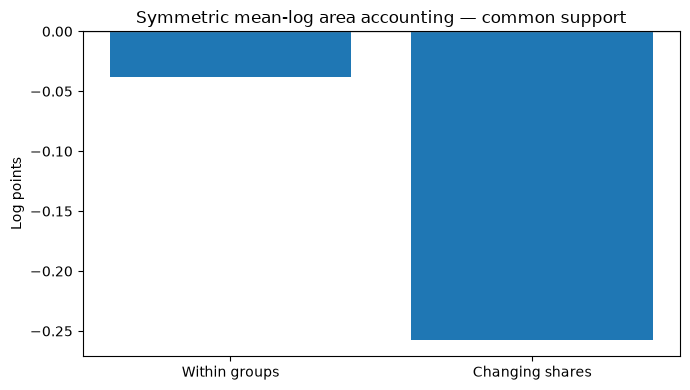

In [20]:
area_decomp_total,area_decomp_detail=symmetric_decomposition(common_data,DESIGNS[DECOMP_DESIGN],'log_area')
area_mix_decomposition=pd.DataFrame([dict(design=DECOMP_DESIGN,metric='mean_log_area_sqm',**area_decomp_total)])
display(area_mix_decomposition)
fig,ax=plt.subplots(figsize=(7,4));ax.bar(['Within groups','Changing shares'],[area_decomp_total['within_log_points'],area_decomp_total['composition_log_points']]);ax.axhline(0,color='gray',lw=1);ax.set(ylabel='Log points',title='Symmetric mean-log area accounting — common support');fig.tight_layout();fig.savefig(FIG/'02_area_decomposition.png',dpi=145);plt.show()
# Size bands constrain, but do not force, within-band area changes to zero.

In [21]:
area2021=area_distribution_yearly.set_index('year').loc[2021,'median_area'];area2025=area_distribution_yearly.set_index('year').loc[2025,'median_area']
area_raw_pct=100*(area2025/area2021-1)
composition_synthesis=pd.DataFrame([dict(metric='Observed P1 median AED/sqm',change_pct=raw_change_pct,population='All P1 Strict endpoint transactions'),dict(metric='Common-support geometric-mean AED/sqm',change_pct=price_decomp_total['geomean_change_pct'],population='Restricted common-support matched groups'),dict(metric='Observed P1 median area',change_pct=area_raw_pct,population='All P1 Strict endpoint transactions'),dict(metric='Common-support geometric-mean area',change_pct=area_decomp_total['geomean_change_pct'],population='Restricted common-support matched groups')])
display(composition_synthesis)
display(Markdown('**Interpretation:** The two symmetric decompositions are identities for *different mean-log outcomes* on the same restricted group universe. Neither decomposes the full residential median. Because AED/sqm uses area in the denominator, the price/area association is partly mechanical; no causal size effect is claimed.'))

,metric,change_pct,population
0,Observed P1 median AED/sqm,64.431581,All P1 Strict endpoint transactions
1,Common-support geometric-mean AED/sqm,55.659928,Restricted common-support matched groups
2,Observed P1 median area,-30.443512,All P1 Strict endpoint transactions
3,Common-support geometric-mean area,-25.608537,Restricted common-support matched groups


**Interpretation:** The two symmetric decompositions are identities for *different mean-log outcomes* on the same restricted group universe. Neither decomposes the full residential median. Because AED/sqm uses area in the denominator, the price/area association is partly mechanical; no causal size effect is claimed.

## 30 — Conditional uncertainty, not population-identification uncertainty
Transaction-level resampling within matched group × endpoint cells estimates conditional variability of group medians under a resampling model; it does **not** address missing communities, missing bedrooms, changing building quality or nonrandom registration. Community-cluster resampling is a separate sensitivity when there are sufficiently many communities. We report seed, replicates and successful replicates, and withhold inference if support fails.

In [22]:
BOOT_REPS=250  # reproducible default; modify only as a documented sensitivity run
BOOT_SEED=SEED
price_index_uncertainty=pd.DataFrame()
boot_samples=np.array([])
if PRIMARY:
    v=eligible_for_design(endpoint,PRIMARY);keys=DESIGNS[PRIMARY]
    supported=detail_indices[PRIMARY][keys+['weight']].copy()
    groups=v.merge(supported[keys],on=keys,how='inner',validate='many_to_one')
    # Construct resampling arrays once. Hold baseline segment weights fixed by design.
    arrays={}
    for k,sub in groups.groupby(keys+['year'],observed=True,sort=False):
        vals=k if isinstance(k,tuple) else (k,)
        arrays[(tuple(vals[:-1]),int(vals[-1]))]=sub.price_per_sqm.to_numpy(dtype=float)
    base_details=detail_indices[PRIMARY]
    local_rng=np.random.default_rng(BOOT_SEED);boots=[]
    segment_keys=[tuple(row[k] for k in keys) for _,row in base_details.iterrows()]
    for b in range(BOOT_REPS):
        lr=[]
        for k in segment_keys:
            a=arrays.get((k,2021));z=arrays.get((k,2025))
            if a is None or z is None:raise AssertionError('Missing bootstrap matched group')
            m0=np.median(a[local_rng.integers(len(a),size=len(a))]);m1=np.median(z[local_rng.integers(len(z),size=len(z))])
            lr.append(np.log(m1/m0))
        boots.append(float(np.dot(base_details.weight.to_numpy(),lr)))
    boot_samples=np.asarray(boots)
    assert len(boot_samples)==BOOT_REPS and np.isfinite(boot_samples).all()
    point=float(price_index_endpoint.set_index('design').loc[PRIMARY,'log_change'])
    lo,hi=np.percentile(boot_samples,[2.5,97.5])
    price_index_uncertainty=pd.DataFrame([dict(design=PRIMARY,method='within-cell transaction bootstrap, fixed groups and weights',replicates=BOOT_REPS,valid_replicates=len(boot_samples),seed=BOOT_SEED,point_change_pct=100*np.expm1(point),lower_change_pct=100*np.expm1(lo),upper_change_pct=100*np.expm1(hi))])
    display(price_index_uncertainty)
else:print('No preselected primary support: conditional bootstrap not estimable.')

,design,method,replicates,valid_replicates,seed,point_change_pct,lower_change_pct,upper_change_pct
0,A_broad,"within-cell transaction bootstrap, fixed group...",250,250,202602,64.806811,64.26966,65.558804


In [23]:
# Paired community resampling captures a different dependence dimension; it does not repair geographic selection.
CLUSTER_REPS=200;price_index_cluster_sensitivity=pd.DataFrame()
if PRIMARY and 'area_id' in DESIGNS[PRIMARY]:
    det=detail_indices[PRIMARY]
    comm=det.groupby('area_id').agg(n_2021=('n_2021','sum'),log_numerator=('weighted_contribution','sum')).reset_index()
    # More defensible cluster bootstrap: resample communities and re-normalize their 2021 transaction weights.
    comm_lr=det.assign(weighted_num=lambda d:d.n_2021*d.log_change).groupby('area_id').agg(weighted_num=('weighted_num','sum'),base_n=('n_2021','sum')).reset_index()
    if len(comm_lr)>=15:
        rr=np.random.default_rng(SEED+1);arr=comm_lr[['weighted_num','base_n']].to_numpy(float);out=[]
        for _ in range(CLUSTER_REPS):
            z=arr[rr.integers(len(arr),size=len(arr))];out.append(z[:,0].sum()/z[:,1].sum())
        lo,hi=np.percentile(out,[2.5,97.5]);price_index_cluster_sensitivity=pd.DataFrame([dict(design=PRIMARY,method='community resample of group-level contributions',communities=len(comm_lr),replicates=CLUSTER_REPS,lower_change_pct=100*np.expm1(lo),upper_change_pct=100*np.expm1(hi))])
        display(price_index_cluster_sensitivity)
    else:print('Community clustering not estimated: fewer than 15 observed clusters.')
else:print('No preselected primary specification or geographic dimension.')

,design,method,communities,replicates,lower_change_pct,upper_change_pct
0,A_broad,community resample of group-level contributions,53,200,55.310223,75.01362


In [24]:
stability_rows=[];loo_rows=[]
for d in DESIGNS:
    for threshold in [20,30,50,100]:
        ans=endpoint_index(d,threshold)
        if ans:stability_rows.append(ans[0])
price_index_stability=pd.DataFrame(stability_rows)
if PRIMARY:
    det=detail_indices[PRIMARY];full=float((det.weight*det.log_change).sum())
    for community in det.area_id.unique():
        sub=det.loc[det.area_id.ne(community)]
        if sub.empty:continue
        change=float(np.dot(sub.n_2021/sub.n_2021.sum(),sub.log_change))
        loo_rows.append(dict(removed_area_id=str(community),change_pct=100*np.expm1(change),change_from_full_pp=100*(np.expm1(change)-np.expm1(full))))
price_leave_one_area_out=pd.DataFrame(loo_rows)
display(price_index_stability[['design','threshold','matched_cells','coverage_2025_pct','change_pct']])
if not price_leave_one_area_out.empty:display(price_leave_one_area_out.reindex(price_leave_one_area_out.change_from_full_pp.abs().sort_values(ascending=False).index).head(10))

,design,threshold,matched_cells,coverage_2025_pct,change_pct
0,A_broad,20,108,71.892357,64.623247
1,A_broad,30,102,69.099027,64.806811
2,A_broad,50,87,67.417105,64.696800
3,A_broad,100,68,63.498955,62.895176
4,B_bedrooms,20,233,59.651770,61.918900
5,B_bedrooms,30,200,58.058135,61.958029
6,B_bedrooms,50,156,49.554095,61.073446
7,B_bedrooms,100,89,38.952962,61.068183
8,C_size_only,20,303,56.935551,61.285245
9,C_size_only,30,248,49.145070,60.875411


,removed_area_id,change_pct,change_from_full_pp
5,330.0,67.873143,3.066331
43,482.0,62.421081,-2.385730
21,412.0,67.054417,2.247605
11,350.0,62.819631,-1.987181
46,485.0,65.865199,1.058388
40,467.0,63.887526,-0.919285
34,458.0,65.586043,0.779232
7,334.0,64.054911,-0.751900
24,435.0,64.115193,-0.691619
51,526.0,65.406255,0.599444


## 34 — Three distinct uncertainty domains
The within-cell bootstrap describes resampling variability conditional on observed groups and fixed 2021 weights; the community reweighting sensitivity probes geographic influence. **Neither** accounts for omitted transactions, unobserved building quality, preferential missing bedrooms, unstable administrative coverage or specification choice. We will not treat a narrow interval as sufficient evidence of a citywide price change.

## 35 — Prespecified robustness and classification policy
Keep the 2021 and 2025 endpoints and group definitions fixed. Contrast alternative thresholds, reference/equal/symmetric weighting, feature requirements, quality flags and major Unit/Villa and Ready/Off-Plan strata. Every table must identify changed target populations. Claim status uses directional/size stability, coverage, sample support, quality sensitivity and observational limits—not the magnitude or sign of the preferred result.

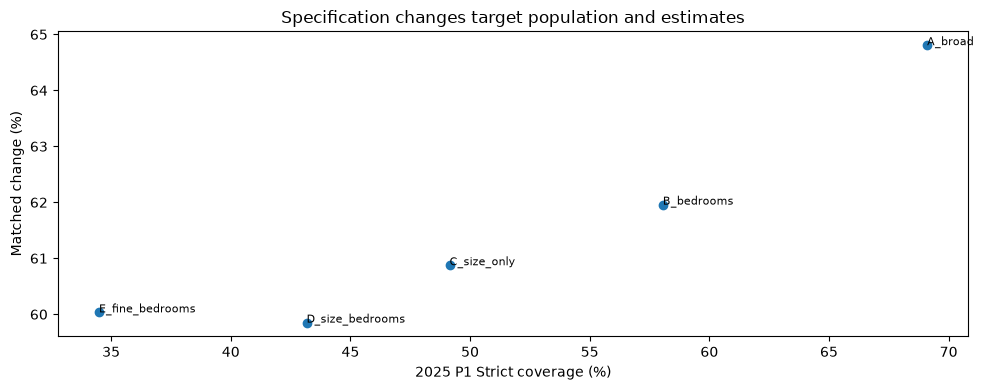

,design,threshold,weight_mode,segment,matched_cells,n_2021,n_2025,coverage_2021_pct,coverage_2025_pct,log_change,change_pct,effective_segments,top5_weight_pct
0,A_broad,30,base,ALL,102,45119,123661,97.445035,69.099027,0.499604,64.806811,39.067201,25.446043
1,A_broad,30,end,ALL,102,45119,123661,97.445035,69.099027,0.513528,67.117649,31.108108,30.953979
2,A_broad,30,symmetric,ALL,102,45119,123661,97.445035,69.099027,0.506566,65.958208,41.851549,24.679949
3,A_broad,30,equal,ALL,102,45119,123661,97.445035,69.099027,0.511571,66.790938,102.000000,4.901961
4,B_bedrooms,30,base,ALL,200,38525,103902,83.203749,58.058135,0.482167,61.958029,85.928426,13.791045
5,B_bedrooms,30,end,ALL,200,38525,103902,83.203749,58.058135,0.512401,66.929483,63.845845,20.197879
6,B_bedrooms,30,symmetric,ALL,200,38525,103902,83.203749,58.058135,0.497284,64.424968,89.754570,14.134684
7,B_bedrooms,30,equal,ALL,200,38525,103902,83.203749,58.058135,0.492243,63.598231,200.000000,2.500000
8,C_size_only,30,base,ALL,248,37556,87951,81.110967,49.145070,0.475460,60.875411,116.627715,10.078283
9,C_size_only,30,end,ALL,248,37556,87951,81.110967,49.145070,0.514399,67.263233,69.977981,20.440927


In [25]:
spec_rows=[]
for d in DESIGNS:
    for weight in ['base','end','symmetric','equal']:
        ans=endpoint_index(d,30,weight_mode=weight)
        if ans:spec_rows.append(ans[0])
price_index_specification_sensitivity=pd.DataFrame(spec_rows)
fig,ax=plt.subplots(figsize=(10,4))
if not price_index_specification_sensitivity.empty:
    z=price_index_specification_sensitivity.query("weight_mode=='base'")
    ax.scatter(z.coverage_2025_pct,z.change_pct)
    for _,r in z.iterrows():ax.annotate(r.design,(r.coverage_2025_pct,r.change_pct),fontsize=8)
ax.set(xlabel='2025 P1 Strict coverage (%)',ylabel='Matched change (%)',title='Specification changes target population and estimates');fig.tight_layout();fig.savefig(FIG/'02_estimate_robustness.png',dpi=145);plt.show()
display(price_index_specification_sensitivity)

In [26]:
# P1 Core comparison: re-use validated flags, do not relabel or repair flagged transactions.
core=f.loc[(f.eligible_residential_core & f.year.isin([2021,2025])),cols].copy()
core['year']=core['year'].astype(int);core['area_id']=core['area_id'].astype('string')
core['room_known']=pd.to_numeric(core.rooms_bucket,errors='coerce').isin([0,1,2,3,4,5]);core['key_known']=core.area_id.notna() & core.property_type_label.isin(['Unit','Villa']) & core.reg_type_label.isin(['Ready','Off-Plan'])
for name,binspec in [('coarse',COARSE),('fine',FINE)]:
    out=pd.Series(pd.NA,index=core.index,dtype='string')
    for ptype,bins in binspec.items():
        m=core.property_type_label.eq(ptype);labels=[f'{ptype}:{i:02d}' for i in range(len(bins)-1)]
        out.loc[m]=pd.cut(core.loc[m,'area_sqm'],bins=bins,labels=labels,right=True).astype('string')
    core['size_'+name]=out
quality_rows=[]
for d in DESIGNS:
    strict=endpoint_index(d,30);broader=endpoint_index(d,30,sample=eligible_for_design(core,d))
    quality_rows.append(dict(design=d,strict_change_pct=strict[0]['change_pct'] if strict else np.nan,core_change_pct=broader[0]['change_pct'] if broader else np.nan,strict_coverage_2025_pct=strict[0]['coverage_2025_pct'] if strict else np.nan,core_coverage_2025_pct=broader[0]['coverage_2025_pct'] if broader else np.nan))
price_quality_sensitivity=pd.DataFrame(quality_rows)
price_quality_sensitivity['core_minus_strict_pp']=price_quality_sensitivity.core_change_pct-price_quality_sensitivity.strict_change_pct
display(price_quality_sensitivity)

,design,strict_change_pct,core_change_pct,strict_coverage_2025_pct,core_coverage_2025_pct,core_minus_strict_pp
0,A_broad,64.806811,66.887673,69.099027,70.486472,2.080862
1,B_bedrooms,61.958029,63.995952,58.058135,59.276271,2.037924
2,C_size_only,60.875411,62.246323,49.145070,50.396732,1.370913
3,D_size_bedrooms,59.850664,60.750936,43.170058,44.018283,0.900272
4,E_fine_bedrooms,60.033272,61.792157,34.493915,35.213062,1.758884


In [27]:
selection_rows=[]
for d in DESIGNS:
    ans=endpoint_index(d,30)
    if ans:
        r=ans[0];selection_rows.append(dict(design=d,needs_bedrooms=('rooms_bucket' in DESIGNS[d]),matched_change_pct=r['change_pct'],coverage_2021_pct=r['coverage_2021_pct'],coverage_2025_pct=r['coverage_2025_pct'],matched_cells=r['matched_cells']))
price_selection_sensitivity=pd.DataFrame(selection_rows)
# Explicit ready-villa coverage under each design and threshold.
villa_rows=[]
for d in DESIGNS:
    ans=endpoint_index(d,30,restrict_to=('property_type_label','Villa'))
    if ans:villa_rows.append(ans[0])
ready_villa_selection=pd.DataFrame(villa_rows)
display(price_selection_sensitivity)
display(ready_villa_selection[['design','matched_cells','coverage_2021_pct','coverage_2025_pct','change_pct']] if not ready_villa_selection.empty else ready_villa_selection)
print('Bedroom unknowns are never imputed; differences across designs combine selection and matching changes, not identified causal biases.')

,design,needs_bedrooms,matched_change_pct,coverage_2021_pct,coverage_2025_pct,matched_cells
0,A_broad,False,64.806811,97.445035,69.099027,102
1,B_bedrooms,True,61.958029,83.203749,58.058135,200
2,C_size_only,False,60.875411,81.110967,49.145070,248
3,D_size_bedrooms,True,59.850664,69.947302,43.170058,250
4,E_fine_bedrooms,True,60.033272,62.491901,34.493915,263


,design,matched_cells,coverage_2021_pct,coverage_2025_pct,change_pct
0,A_broad,28,91.818520,73.101023,91.911138
1,B_bedrooms,35,56.889178,56.719949,86.465489
2,C_size_only,50,58.646337,51.803069,87.922902
3,D_size_bedrooms,36,40.823726,40.070332,84.046393
4,E_fine_bedrooms,30,33.711417,26.010230,88.813585


Bedroom unknowns are never imputed; differences across designs combine selection and matching changes, not identified causal biases.


In [28]:
robust_rows=[]
if not price_index_endpoint.empty:
    for _,r in price_index_endpoint.iterrows():
        eligible_coverage=min(r.coverage_2021_pct,r.coverage_2025_pct)
        thresholds=price_index_stability.query('design==@r.design')['change_pct'].dropna().to_numpy()
        orientation_consistent=bool(len(thresholds) and (np.all(thresholds>=0) or np.all(thresholds<=0)))
        quality=price_quality_sensitivity.query('design==@r.design').iloc[0]
        qa_gap=abs(quality.core_minus_strict_pp) if pd.notna(quality.core_minus_strict_pp) else np.nan
        enough=(r.matched_cells>=30 and eligible_coverage>=60 and r.effective_segments>=10)
        status='QUALIFIED' if enough and orientation_consistent and (pd.isna(qa_gap) or qa_gap<=5) else 'INCONCLUSIVE'
        robust_rows.append(dict(design=r.design,matched_change_pct=r.change_pct,min_endpoint_coverage_pct=eligible_coverage,matched_cells=r.matched_cells,effective_segments=r.effective_segments,threshold_direction_stable=orientation_consistent,quality_gap_pp=qa_gap,decision=status,limitation='Observed matched transactions only; uncontrolled building/quality composition'))
price_research_robustness_gate=pd.DataFrame(robust_rows)
display(price_research_robustness_gate)

,design,matched_change_pct,min_endpoint_coverage_pct,matched_cells,effective_segments,threshold_direction_stable,quality_gap_pp,decision,limitation
0,A_broad,64.806811,69.099027,102,39.067201,True,2.080862,QUALIFIED,Observed matched transactions only; uncontroll...
1,B_bedrooms,61.958029,58.058135,200,85.928426,True,2.037924,INCONCLUSIVE,Observed matched transactions only; uncontroll...
2,C_size_only,60.875411,49.145070,248,116.627715,True,1.370913,INCONCLUSIVE,Observed matched transactions only; uncontroll...
3,D_size_bedrooms,59.850664,43.170058,250,114.153818,True,0.900272,INCONCLUSIVE,Observed matched transactions only; uncontroll...
4,E_fine_bedrooms,60.033272,34.493915,263,122.780430,True,1.758884,INCONCLUSIVE,Observed matched transactions only; uncontroll...


## 40 — Historical consistency is a secondary estimand
An annual **fixed-basket** index requires sufficient observations for the same reference groups in each published year. A **chain-linked** index matches successive years and can drift as the link's support changes. Neither should be presented as a full-market constant-quality index. Gaps must remain gaps; missing annual links are not interpolated.

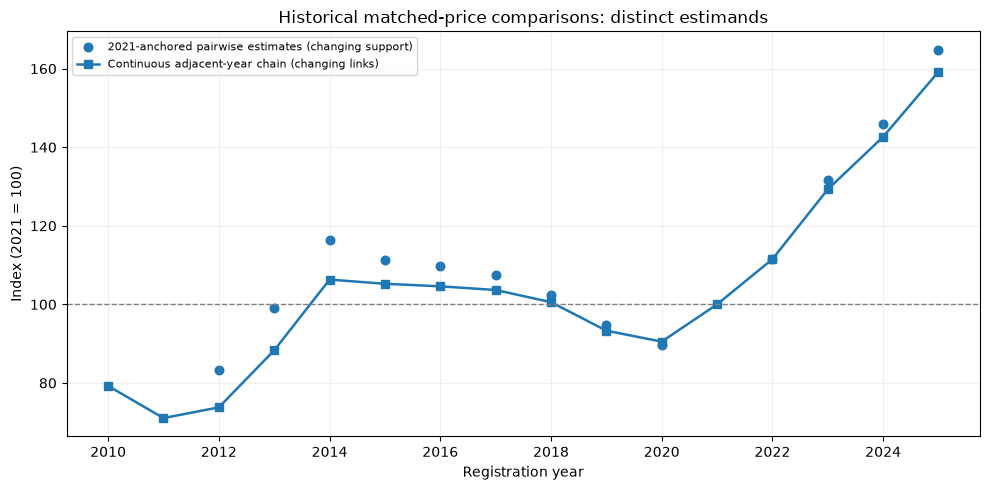

,year,method,index_2021_100,matched_groups,coverage_pct,base_coverage_pct,effective_groups,supported
10,2020,2021-anchored pairwise,89.689743,88.0,94.999426,95.496955,37.567457,True
11,2021,Reference anchor only,100.000000,NaN,NaN,NaN,NaN,True
12,2022,2021-anchored pairwise,111.516282,99.0,95.525438,97.680446,39.200534,True
13,2023,2021-anchored pairwise,131.773485,99.0,89.427342,97.112436,38.807002,True
14,2024,2021-anchored pairwise,145.796303,101.0,76.434469,95.859790,38.183062,True
15,2025,2021-anchored pairwise,164.806811,102.0,69.099027,97.445035,39.067201,True


,year,link_log_change,link_coverage_pct,base_coverage_pct,matched_groups,effective_groups,supported
9,2020,-0.030376,92.397750,96.930955,88,34.440577,True
10,2021,0.099618,95.496955,94.999426,88,40.470899,True
11,2022,0.109000,95.525438,97.680446,99,39.200534,True
12,2023,0.147755,94.641936,98.320507,108,35.873129,True
13,2024,0.098438,90.376147,99.036036,125,34.931617,True
14,2025,0.109932,95.853868,99.296855,136,45.953154,True


,year,index_2021_100,continuous_support
10,2020,90.518318,True
11,2021,100.000000,True
12,2022,111.516282,True
13,2023,129.272924,True
14,2024,142.645713,True
15,2025,159.221434,True


Historical interpretation: pairwise endpoints use year-specific matched populations; chain links use year-specific matched groups. Neither is a fixed 2010–2025 constant-quality property basket.


In [35]:

# 41 — Historical matching: distinguish pairwise comparisons
# from a continuously supported chain-linked index.
#
# IMPORTANT:
# Pairwise 2021-anchored estimates may use different matched
# segments in each year. They are NOT a fixed-basket time series.

MIN_GROUP_N = 30
MIN_LINK_GROUPS = 30
MIN_LINK_COVERAGE_PCT = 60.0
MIN_EFFECTIVE_GROUPS = 10.0

historical_rows = []
chain_rows = []

def historical_pair_estimate(frame, keys, base_year, target_year):
    """Compare two years using matched segments and base-year weights."""
    pair = frame.loc[
        frame["year"].isin([base_year, target_year])
    ].copy()

    stats = (
        pair.groupby(keys + ["year"], observed=True)
        .agg(
            n=("price_per_sqm", "size"),
            median_psm=("price_per_sqm", "median")
        )
        .reset_index()
    )

    counts = stats.pivot(
        index=keys,
        columns="year",
        values="n"
    ).fillna(0)

    medians = stats.pivot(
        index=keys,
        columns="year",
        values="median_psm"
    )

    if base_year not in counts or target_year not in counts:
        return None

    supported = (
        counts[base_year].ge(MIN_GROUP_N) &
        counts[target_year].ge(MIN_GROUP_N)
    )

    if not supported.any():
        return None

    n_base = counts.loc[supported, base_year]
    n_target = counts.loc[supported, target_year]

    p_base = medians.loc[supported, base_year]
    p_target = medians.loc[supported, target_year]

    assert p_base.gt(0).all()
    assert p_target.gt(0).all()

    weights = n_base / n_base.sum()

    delta = float(
        np.dot(
            weights.to_numpy(),
            np.log(p_target / p_base).to_numpy()
        )
    )

    parent_base = int(res["year"].eq(base_year).sum())
    parent_target = int(res["year"].eq(target_year).sum())

    coverage_base = (
        100 * n_base.sum() / parent_base
        if parent_base else np.nan
    )

    coverage_target = (
        100 * n_target.sum() / parent_target
        if parent_target else np.nan
    )

    effective_groups = float(
        1 / np.square(weights).sum()
    )

    return {
        "base_year": base_year,
        "target_year": target_year,
        "matched_groups": int(supported.sum()),
        "matched_base_n": int(n_base.sum()),
        "matched_target_n": int(n_target.sum()),
        "coverage_base_pct": float(coverage_base),
        "coverage_target_pct": float(coverage_target),
        "effective_groups": effective_groups,
        "log_change": delta,
        "index_base_100": float(100 * np.exp(delta))
    }


if PRIMARY is not None:

    keys = DESIGNS[PRIMARY]
    history = eligible_for_design(res, PRIMARY)

    # A. 2021-anchored pairwise comparisons.
    # Every year's eligible matched set is calculated independently.
    for year in range(2010, 2026):

        if year == 2021:
            historical_rows.append({
                "year": 2021,
                "method": "Reference anchor only",
                "index_2021_100": 100.0,
                "matched_groups": np.nan,
                "coverage_pct": np.nan,
                "base_coverage_pct": np.nan,
                "effective_groups": np.nan,
                "supported": True
            })
            continue

        result = historical_pair_estimate(
            history, keys, 2021, year
        )

        if result is None:
            historical_rows.append({
                "year": year,
                "method": "2021-anchored pairwise",
                "index_2021_100": np.nan,
                "matched_groups": 0,
                "coverage_pct": np.nan,
                "base_coverage_pct": np.nan,
                "effective_groups": np.nan,
                "supported": False
            })
            continue

        adequate = (
            result["matched_groups"] >= MIN_LINK_GROUPS and
            result["coverage_base_pct"] >= MIN_LINK_COVERAGE_PCT and
            result["coverage_target_pct"] >= MIN_LINK_COVERAGE_PCT and
            result["effective_groups"] >= MIN_EFFECTIVE_GROUPS
        )

        historical_rows.append({
            "year": year,
            "method": "2021-anchored pairwise",
            "index_2021_100":
                result["index_base_100"] if adequate else np.nan,
            "matched_groups": result["matched_groups"],
            "coverage_pct": result["coverage_target_pct"],
            "base_coverage_pct": result["coverage_base_pct"],
            "effective_groups": result["effective_groups"],
            "supported": bool(adequate)
        })

    # B. Consecutive-year matching.
    # Each link has its own coverage and support test.
    for year in range(2011, 2026):

        result = historical_pair_estimate(
            history, keys, year - 1, year
        )

        if result is None:
            chain_rows.append({
                "year": year,
                "link_log_change": np.nan,
                "link_coverage_pct": np.nan,
                "base_coverage_pct": np.nan,
                "matched_groups": 0,
                "effective_groups": np.nan,
                "supported": False
            })
            continue

        adequate = (
            result["matched_groups"] >= MIN_LINK_GROUPS and
            result["coverage_base_pct"] >= MIN_LINK_COVERAGE_PCT and
            result["coverage_target_pct"] >= MIN_LINK_COVERAGE_PCT and
            result["effective_groups"] >= MIN_EFFECTIVE_GROUPS
        )

        chain_rows.append({
            "year": year,
            "link_log_change":
                result["log_change"] if adequate else np.nan,
            "link_coverage_pct": result["coverage_target_pct"],
            "base_coverage_pct": result["coverage_base_pct"],
            "matched_groups": result["matched_groups"],
            "effective_groups": result["effective_groups"],
            "supported": bool(adequate)
        })


price_index_historical = pd.DataFrame(historical_rows)
price_chain_links = pd.DataFrame(chain_rows)

# C. Construct a 2021-anchored chain.
# Stop on either side of 2021 when a required link fails.

chain_index_rows = [{
    "year": 2021,
    "index_2021_100": 100.0,
    "continuous_support": True
}]

if not price_chain_links.empty:

    links = price_chain_links.set_index("year")

    for direction, years in [
        (1, range(2022, 2026)),
        (-1, range(2020, 2009, -1))
    ]:

        value = 100.0
        continuous = True

        for year in years:

            link_year = (
                year if direction == 1 else year + 1
            )

            if link_year not in links.index:
                continuous = False
            else:
                row = links.loc[link_year]
                if (
                    not bool(row["supported"]) or
                    not np.isfinite(row["link_log_change"])
                ):
                    continuous = False

            if continuous:
                value *= np.exp(
                    direction * float(
                        links.loc[link_year, "link_log_change"]
                    )
                )
            else:
                value = np.nan

            chain_index_rows.append({
                "year": year,
                "index_2021_100": float(value),
                "continuous_support": bool(continuous)
            })


price_chain_index = (
    pd.DataFrame(chain_index_rows)
    .sort_values("year")
    .reset_index(drop=True)
)

price_index_historical_coverage = (
    price_index_historical[
        [
            "year",
            "matched_groups",
            "coverage_pct",
            "base_coverage_pct",
            "effective_groups",
            "supported"
        ]
    ].copy()
    if not price_index_historical.empty
    else pd.DataFrame()
)

# D. Reconciliation and interpretation checks.
assert not price_chain_index.empty
assert np.isclose(
    price_chain_index.loc[
        price_chain_index["year"].eq(2021),
        "index_2021_100"
    ].iloc[0],
    100.0
)

anchor = price_index_historical.loc[
    price_index_historical["year"].eq(2021)
]

assert anchor["coverage_pct"].isna().all(), (
    "The standalone 2021 anchor must not claim 100% matched coverage."
)

if PRIMARY:
    endpoint_value = (
        100 + price_index_endpoint.set_index("design")
        .loc[PRIMARY, "change_pct"]
    )

    pairwise_2025 = price_index_historical.loc[
        price_index_historical["year"].eq(2025),
        "index_2021_100"
    ].iloc[0]

    if np.isfinite(pairwise_2025):
        assert np.isclose(
            pairwise_2025, endpoint_value,
            atol=1e-8
        ), "2025 pairwise result differs from endpoint estimator"


# E. Plot two distinctly labeled estimands.
fig, ax = plt.subplots(figsize=(10, 5))

if not price_index_historical.empty:
    pairwise = price_index_historical[
        price_index_historical["year"].ne(2021)
    ]

    ax.scatter(
        pairwise["year"],
        pairwise["index_2021_100"],
        marker="o",
        s=38,
        label="2021-anchored pairwise estimates (changing support)"
    )

if not price_chain_index.empty:
    ax.plot(
        price_chain_index["year"],
        price_chain_index["index_2021_100"],
        marker="s",
        linewidth=1.8,
        label="Continuous adjacent-year chain (changing links)"
    )

ax.axhline(
    100, linestyle="--", linewidth=1,
    color="gray"
)

ax.set(
    xlabel="Registration year",
    ylabel="Index (2021 = 100)",
    title="Historical matched-price comparisons: distinct estimands"
)

ax.legend(fontsize=8)
ax.grid(alpha=0.2)

fig.tight_layout()

fig.savefig(
    FIG / "02_historical_price_index.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

display(price_index_historical.tail(6))
display(price_chain_links.tail(6))
display(price_chain_index.tail(6))

print(
    "Historical interpretation: pairwise endpoints use "
    "year-specific matched populations; chain links use "
    "year-specific matched groups. Neither is a fixed "
    "2010–2025 constant-quality property basket."
)


In [36]:
# Alternative method on IDENTICAL matched support: fixed-base weighted mean-log group price.
price_method_comparison=pd.DataFrame()
if PRIMARY:
    keys=DESIGNS[PRIMARY];a=common_data.groupby(keys+['year'],observed=True).agg(n=('log_psm','size'),mean_log=('log_psm','mean')).reset_index()
    wide=a.pivot(index=keys,columns='year',values='mean_log');cnt=a.pivot(index=keys,columns='year',values='n')
    ww=cnt[2021]/cnt[2021].sum();delta=float(np.dot(ww,wide[2025]-wide[2021]))
    main=price_index_endpoint.set_index('design').loc[PRIMARY,'change_pct']
    price_method_comparison=pd.DataFrame([dict(design=PRIMARY,method='Fixed-2021 group median log change',change_pct=main,matched_groups=len(ww)),dict(design=PRIMARY,method='Fixed-2021 group mean-log change',change_pct=100*np.expm1(delta),matched_groups=len(ww))])
    display(price_method_comparison)
print('A hedonic regression is deliberately withheld: no credible universal building-quality controls or external validation. A different grouped outcome is a more transparent corroboration.')

,design,method,change_pct,matched_groups
0,A_broad,Fixed-2021 group median log change,64.806811,102
1,A_broad,Fixed-2021 group mean-log change,64.886790,102


A hedonic regression is deliberately withheld: no credible universal building-quality controls or external validation. A different grouped outcome is a more transparent corroboration.


In [37]:
validation_rows=[]
def check(name,ok,detail=''):
    validation_rows.append(dict(check=name,passed=bool(ok),details=str(detail)))
check('Source SHA', source.sha256==SHA)
check('Source schema', len(raw.columns)==20)
check('No source mutation',all(raw[c].equals(f[c]) for c in raw.columns))
check('P2 subset of P1',(P2&~P1).sum()==0)
check('P1 positive prices',res.price_per_sqm.gt(0).all())
check('Unique transactions',res.transaction_id.is_unique)
check('Coverage <=100%',price_matching_feasibility[['total_2021_pct','total_2025_pct']].le(100.000001).all().all())
check('Segment group-period uniqueness',not price_segment_yearly.duplicated(['design','year']+base_keys+['rooms_bucket','size_coarse','size_fine']).any())
check('Decomposition price identity',np.isclose(price_decomp_total['total_log_points'],price_decomp_total['within_log_points']+price_decomp_total['composition_log_points'],atol=1e-10))
check('Decomposition area identity',np.isclose(area_decomp_total['total_log_points'],area_decomp_total['within_log_points']+area_decomp_total['composition_log_points'],atol=1e-10))
check('Common coverage reconciled',int(common_data.year.eq(2021).sum())==price_decomp_total['n_2021'] and int(common_data.year.eq(2025).sum())==price_decomp_total['n_2025'])
check('Raw endpoint years',set([2021,2025]).issubset(set(raw_residential_price_yearly.year)))
check('No 2026 in historical',res.year.max()<=2025)
check('Primary selection independent of outcome',PRIMARY is None or PRIMARY in DESIGNS)
check('Finite index values',price_index_endpoint.change_pct.map(np.isfinite).all() if not price_index_endpoint.empty else True)
check('Bootstrap valid',price_index_uncertainty.valid_replicates.eq(BOOT_REPS).all() if not price_index_uncertainty.empty else True)
check('Historical chain anchor',not price_chain_index.empty and np.isclose(price_chain_index.loc[price_chain_index.year.eq(2021),'index_2021_100'].iloc[0],100))
check('All matching candidates screened',set(DESIGNS)==set(price_matching_feasibility.design))
price_research_validation=pd.DataFrame(validation_rows)
display(price_research_validation)
print('Audit checks',int(price_research_validation.passed.sum()),'/',len(price_research_validation))
assert price_research_validation.passed.all(), 'Blocked: mathematical/data integrity check failed'

,check,passed,details
0,Source SHA,True,
1,Source schema,True,
2,No source mutation,True,
3,P2 subset of P1,True,
4,P1 positive prices,True,
5,Unique transactions,True,
6,Coverage <=100%,True,
7,Segment group-period uniqueness,True,
8,Decomposition price identity,True,
9,Decomposition area identity,True,


Audit checks 18 / 18


In [38]:
# Research decisions distinguish population support from sampling intervals and unresolved omitted variables.
decision_rows=[]
for _,r in price_research_robustness_gate.iterrows():
    decision_rows.append(dict(research_question='RQ01',estimand='Fixed-2021-weight group-median change',design=r.design,estimate_pct=r.matched_change_pct,matched_coverage_min_pct=r.min_endpoint_coverage_pct,uncertainty_interval='Conditional/bootstrap only' if r.design==PRIMARY and not price_index_uncertainty.empty else 'Not estimated',decision=r.decision,restriction=r.limitation))
decision_rows.append(dict(research_question='RQ01',estimand='Symmetric mean-log AED/sqm decomposition',design=DECOMP_DESIGN,estimate_pct=price_decomp_total['geomean_change_pct'],matched_coverage_min_pct=coverage_decomp.coverage_pct.min(),uncertainty_interval='Not estimated',decision='QUALIFIED',restriction='Exact only for common-support geometric-mean outcome; noncausal'))
decision_rows.append(dict(research_question='RQ02',estimand='Symmetric mean-log area decomposition',design=DECOMP_DESIGN,estimate_pct=area_decomp_total['geomean_change_pct'],matched_coverage_min_pct=coverage_decomp.coverage_pct.min(),uncertainty_interval='Not estimated',decision='QUALIFIED',restriction='Exact only for common-support mean log area; not median size'))
price_research_decisions=pd.DataFrame(decision_rows)
display(price_research_decisions)
print('Primary:',PRIMARY or 'no fully supported primary; restrict interpretation')

,research_question,estimand,design,estimate_pct,matched_coverage_min_pct,uncertainty_interval,decision,restriction
0,RQ01,Fixed-2021-weight group-median change,A_broad,64.806811,69.099027,Conditional/bootstrap only,QUALIFIED,Observed matched transactions only; uncontroll...
1,RQ01,Fixed-2021-weight group-median change,B_bedrooms,61.958029,58.058135,Not estimated,INCONCLUSIVE,Observed matched transactions only; uncontroll...
2,RQ01,Fixed-2021-weight group-median change,C_size_only,60.875411,49.145070,Not estimated,INCONCLUSIVE,Observed matched transactions only; uncontroll...
3,RQ01,Fixed-2021-weight group-median change,D_size_bedrooms,59.850664,43.170058,Not estimated,INCONCLUSIVE,Observed matched transactions only; uncontroll...
4,RQ01,Fixed-2021-weight group-median change,E_fine_bedrooms,60.033272,34.493915,Not estimated,INCONCLUSIVE,Observed matched transactions only; uncontroll...
5,RQ01,Symmetric mean-log AED/sqm decomposition,A_broad,55.659928,69.099027,Not estimated,QUALIFIED,Exact only for common-support geometric-mean o...
6,RQ02,Symmetric mean-log area decomposition,A_broad,-25.608537,69.099027,Not estimated,QUALIFIED,Exact only for common-support mean log area; n...


Primary: A_broad


In [39]:
# Export only actually calculated nonempty evidence; read every artifact back.
outputs={
'02_source_manifest':manifest,'02_price_cohort_coverage':price_cohort_coverage,'02_room_selection':room_selection,
'02_matching_feasibility':price_matching_feasibility,'02_price_segment_yearly':price_segment_yearly,
'02_raw_residential_price_yearly':raw_residential_price_yearly,'02_price_distribution_by_segment':price_distribution_by_segment,
'02_area_distribution_yearly':area_distribution_yearly,'02_residential_size_mix':residential_size_mix,
'02_price_index_endpoint':price_index_endpoint,'02_price_index_by_segment':price_index_by_segment,
'02_price_index_contributions':price_index_contributions,'02_price_comparison_summary':price_comparison_summary,
'02_price_decomposition_population':price_decomposition_population,'02_price_mix_decomposition':price_mix_decomposition,
'02_price_decomposition_detail':price_decomp_detail,'02_decomposition_coverage':decomposition_coverage,
'02_area_mix_decomposition':area_mix_decomposition,'02_area_decomposition_detail':area_decomp_detail,
'02_price_index_uncertainty':price_index_uncertainty,'02_price_index_cluster_sensitivity':price_index_cluster_sensitivity,
'02_price_index_stability':price_index_stability,'02_price_leave_one_area_out':price_leave_one_area_out,
'02_price_index_specification_sensitivity':price_index_specification_sensitivity,
'02_price_quality_sensitivity':price_quality_sensitivity,'02_price_selection_sensitivity':price_selection_sensitivity,
'02_ready_villa_selection':ready_villa_selection,'02_price_research_robustness_gate':price_research_robustness_gate,
'02_price_index_historical':price_index_historical,'02_price_chain_links':price_chain_links,'02_price_chain_index':price_chain_index,'02_price_index_historical_coverage':price_index_historical_coverage,
'02_price_method_comparison':price_method_comparison,'02_price_research_validation':price_research_validation,
'02_price_research_decisions':price_research_decisions}
export_rows=[]
for stem,frame in outputs.items():
    if not isinstance(frame,pd.DataFrame) or frame.empty:continue
    # csv is the portable audit and Parquet is the downstream typed aggregate.
    a=OUT/f'{stem}.csv';b=AGG/f'{stem}.parquet'
    frame.to_csv(a,index=False);frame.to_parquet(b,index=False,engine='pyarrow')
    c=pd.read_csv(a);d=pd.read_parquet(b,engine='pyarrow')
    assert len(c)==len(frame)==len(d)
    assert list(d.columns)==list(frame.columns) and list(c.columns)==list(frame.columns)
    pd.testing.assert_frame_equal(frame.reset_index(drop=True),d.reset_index(drop=True),check_dtype=False,check_exact=False,rtol=1e-10,atol=1e-10)
    export_rows.append(dict(name=stem,rows=len(frame),csv_bytes=a.stat().st_size,parquet_bytes=b.stat().st_size,sha256=SHA))
price_research_exports=pd.DataFrame(export_rows)
display(price_research_exports)
print('Validated exported evidence:',len(price_research_exports),'paired CSV/Parquet outputs')

,name,rows,csv_bytes,parquet_bytes,sha256
0,02_source_manifest,1,187,5219,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
1,02_price_cohort_coverage,64,3758,7443,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
2,02_room_selection,123,8017,8520,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
3,02_matching_feasibility,20,4169,12736,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
4,02_price_segment_yearly,10553,1136200,288525,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
5,02_raw_residential_price_yearly,16,2814,8122,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
6,02_price_distribution_by_segment,64,9325,11140,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
7,02_area_distribution_yearly,16,1176,6038,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
8,02_residential_size_mix,747,27155,7324,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...
9,02_price_index_endpoint,5,928,8535,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...


Validated exported evidence: 35 paired CSV/Parquet outputs


In [41]:
# Final executive narrative calculated from evidence; withhold any unsupported marketwide claim.
assert price_research_validation.passed.all()
lines=['## Notebook 02 — Evidence-based price composition assessment',
       f'**Source SHA-256:** `{source.sha256}`. **Primary period:** 2021 vs 2025. **P1 Strict 2010–2025:** {int(P1.sum()):,} transactions.',
       f'**Raw P1 Strict median AED/sqm:** {raw0:,.2f} → {raw1:,.2f}; change **{raw_change_pct:+.2f}%**. This is composition-sensitive.',
       f'**Raw median sold area:** {area2021:,.2f} → {area2025:,.2f} sqm; change **{area_raw_pct:+.2f}%**.',
       f'**Primary specification selected by support only:** `{PRIMARY or "NONE"}`.']
if PRIMARY:
    row=price_index_endpoint.set_index('design').loc[PRIMARY]
    lines.append(f'**Matched group-median geometric change:** **{row.change_pct:+.2f}%** over {int(row.matched_cells)} groups; coverage **{row.coverage_2021_pct:.1f}% (2021)** / **{row.coverage_2025_pct:.1f}% (2025)** of P1 Strict. Effective weighted groups: {row.effective_segments:.1f}.')
    if not price_index_uncertainty.empty:
        x=price_index_uncertainty.iloc[0];lines.append(f'**Within-cell conditional bootstrap (2.5–97.5%):** {x.lower_change_pct:+.2f}% to {x.upper_change_pct:+.2f}% ({int(x.valid_replicates)} reps); excludes selection/model uncertainty.')
else:lines.append('**General adjusted estimate withheld:** no prespecified matching design passed the feasibility screen.')
lines.extend([f'**Exact common-support mean-log AED/sqm decomposition:** within **{price_decomp_total["within_log_points"]:+.4f}** and composition **{price_decomp_total["composition_log_points"]:+.4f}** log points (total {price_decomp_total["total_log_points"]:+.4f}); **NOT** a decomposition of the raw median.',f'**Exact common-support mean-log area decomposition:** within **{area_decomp_total["within_log_points"]:+.4f}** and composition **{area_decomp_total["composition_log_points"]:+.4f}** log points.',
'**Restrictions:** Nonrandom bedroom completeness (particularly Ready villas), limited matched endpoint representation, geographic entry/exit, within-group quality changes and no unique physical-unit ID. Index weights describe recorded transaction composition, not dwelling stock.',
'**Scientific conclusion:** Conditional matched-group movements are descriptive estimates for the explicitly supported observed cohorts, not causal effects, repeat-sales appreciation, a recovered citywide constant-quality price index or investment returns.',
'**Handoff:** Separate community research must carry its own coverage and support checks, not inherit this endpoint result automatically.'])
display(Markdown('\n\n'.join(lines)))
print('Validation:',int(price_research_validation.passed.sum()),'/',len(price_research_validation),'passed. Exports:',len(price_research_exports))

## Notebook 02 — Evidence-based price composition assessment

**Source SHA-256:** `8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b39384561777afb8425417e`. **Primary period:** 2021 vs 2025. **P1 Strict 2010–2025:** 901,642 transactions.

**Raw P1 Strict median AED/sqm:** 11,037.74 → 18,149.52; change **+64.43%**. This is composition-sensitive.

**Raw median sold area:** 109.58 → 76.22 sqm; change **-30.44%**.

**Primary specification selected by support only:** `A_broad`.

**Matched group-median geometric change:** **+64.81%** over 102 groups; coverage **97.4% (2021)** / **69.1% (2025)** of P1 Strict. Effective weighted groups: 39.1.

**Within-cell conditional bootstrap (2.5–97.5%):** +64.27% to +65.56% (250 reps); excludes selection/model uncertainty.

**Exact common-support mean-log AED/sqm decomposition:** within **+0.5105** and composition **-0.0680** log points (total +0.4425); **NOT** a decomposition of the raw median.

**Exact common-support mean-log area decomposition:** within **-0.0379** and composition **-0.2579** log points.

**Restrictions:** Nonrandom bedroom completeness (particularly Ready villas), limited matched endpoint representation, geographic entry/exit, within-group quality changes and no unique physical-unit ID. Index weights describe recorded transaction composition, not dwelling stock.

**Scientific conclusion:** Conditional matched-group movements are descriptive estimates for the explicitly supported observed cohorts, not causal effects, repeat-sales appreciation, a recovered citywide constant-quality price index or investment returns.

**Handoff:** Separate community research must carry its own coverage and support checks, not inherit this endpoint result automatically.

Validation: 18 / 18 passed. Exports: 35
